# Create figures for the report
## 1. Setup

In [42]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import ListedColormap
from PIL import Image

REPO_ROOT = Path("..").resolve()
FRAMES_DIR = Path("/Users/amynguyen/Documents/MQ/(26_2) FOSE7902 - Advanced STEM Research Placement/WAD/wad_dataset_v2/src_data")
FIG_DIR = REPO_ROOT / "results" / "figures"
OUTS = REPO_ROOT / "results" / "outputs"

CLIP = "20240914_c2b43e749bd87dd58fbd3fc5a436171d_2m23s.frame"
SUBSET = next(p.parent.name for p in OUTS.glob("*/hints.jsonl")
              if CLIP in set(pd.read_json(p, lines=True).clip_id))
OUT, CACHE = OUTS / SUBSET, OUTS / SUBSET / "cache"

hints = pd.read_json(OUT / "hints.jsonl", lines=True)
ranking = pd.read_parquet(OUT / "ranking.parquet")
det = pd.read_parquet(OUT / "detections.parquet")
objects = pd.read_parquet(OUT / "objects.parquet")
motion8 = pd.read_parquet(OUT / "motion_frame8.parquet")
GEO = pd.read_parquet(OUT / "frame_geometry.parquet").set_index(["clip_id", "frame"])
print("clip is in:", SUBSET)

clip is in: test


In [43]:
CAM_HEIGHT, CORRIDOR_HALF, CORRIDOR_LEN = 1.5, 0.6, 8.0
HFOV_LANDSCAPE, HFOV_PORTRAIT = 70.0, 43.0
DIST_SCALE = 8.0
SIDE_GAP, SIDE_W = [0, 0.5, 1.5, 3.0, 5.0], [1.0, 0.7, 0.4, 0.15, 0.0]
DT, DEFAULT_WALK = 1 / 3, 1.2
STATIC_CATS = {"pole", "sign", "tree_plant", "fence_railing", "barrier_cone", "furniture_stall",
               "street_object", "wall_door", "stairs_step", "curb_edge", "hole_uneven", "water"}
SURFACE_COLORS = [(0.10, 0.75, 0.25), (0.95, 0.80, 0.10), (0.60, 0.90, 0.40), (0.10, 0.40, 0.95),
                  (1.00, 0.50, 0.00), (0.60, 0.20, 0.80), (0.50, 0.50, 0.50)]
SURFACE_NAMES = ["walk", "road", "terrain", "water", "stairs", "fence", "wall"]
SEG_CMAP = ListedColormap([(0, 0, 0, 0)] + [(*c, 1) for c in SURFACE_COLORS])
RANK_COLORS = {1: "red", 2: "darkorange", 3: "gold"}
LEVEL_STYLE = {"stop": ("STOP", "red"), "move": ("MOVE", "orangered"), "slow": ("SLOW DOWN", "darkorange"),
               "caution": ("CAUTION", "goldenrod"), "clear": ("CLEAR", "green")}

frame_path = lambda clip, k: FRAMES_DIR / clip / f"{k}.jpg"

def intrinsics(w, h):
    hfov = HFOV_LANDSCAPE if w >= h else HFOV_PORTRAIT
    return (w / 2) / np.tan(np.radians(hfov) / 2), w / 2, h / 2

def ground_axes(a):
    fwd = np.array([0, 0, 1.0]) - a[2] * a
    fwd /= np.linalg.norm(fwd)
    return fwd, np.cross(fwd, a)

def project(P, f, cx, cy):
    return f * P[0] / P[2] + cx, f * P[1] / P[2] + cy

def rigid_2d(A, B):
    """Rotation R and translation t with B ≈ R @ A + t (2-D least squares, Kabsch)."""
    if len(A) == 1:
        return np.eye(2), B[0] - A[0]
    ca, cb = A.mean(0), B.mean(0)
    U, _, Vt = np.linalg.svd((A - ca).T @ (B - cb))
    R = (U @ Vt).T
    if np.linalg.det(R) < 0:
        Vt[-1] *= -1; R = (U @ Vt).T
    return R, cb - R @ ca

def to_h(R, t):
    M = np.eye(3); M[:2, :2] = R; M[:2, 2] = t
    return M

def badge(ax, x, y, num, color):
    ax.scatter(x, y, s=110, color=color, edgecolor="white", linewidth=1.5, zorder=5, clip_on=True)
    ax.text(x, y, str(num), fontsize=6, ha="center", va="center", color="white", fontweight="bold", zorder=6, clip_on=True)

In [44]:
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300, "font.size": 6})
LABEL, TITLE, LEGEND, BADGE = 5, 9, 5, 70 
CORR = "#FFD400"                                   # walking corridor, same in every figure
MOTION_COLORS = {"crossing": "tab:red", "approaching": "tab:orange", "same_direction": "tab:green",
                 "moving_away": "tab:blue", "static": "grey", "unknown": "lightgrey"}
CAT_COLORS = {c: plt.cm.tab20(i % 20) for i, c in enumerate(sorted(det.category.unique()))}

W, H = Image.open(frame_path(CLIP, 8)).size
PORTRAIT = H > W
r = ranking[ranking.clip_id == CLIP].reset_index(drop=True)
h = hints[hints.clip_id == CLIP].iloc[0]
gr = GEO.loc[(CLIP, 8)]
d8 = det[(det.clip_id == CLIP) & (det.frame == 8)].merge(
    objects[["clip_id", "frame", "track_id", "dist_m"]], on=["clip_id", "frame", "track_id"], how="left")
m8 = motion8[motion8.clip_id == CLIP]
motion_of = m8.set_index("track_id").motion
top3 = r.head(3) if h.level != "clear" else r.head(0)

# bird's-eye limits fitted to what matters in this scene
YMAX = float(np.clip((top3.forward_m.max() if len(top3) else 8) + 2, 8, 16))
XMAX = float(np.clip((r.head(6).lateral_m.abs().max() if len(r) else 3) + 1.5, 4, 8))
in_view = lambda df: df[(df.lateral_m.abs() <= XMAX) & df.forward_m.between(-3, YMAX)]
print(h.level, "|", "portrait" if PORTRAIT else "landscape", "|", len(d8), "detections |", len(r), "candidates")

slow | landscape | 18 detections | 6 candidates


In [45]:
def show(ax, title):
    ax.imshow(Image.open(frame_path(CLIP, 8)))
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis("off")
    ax.set_title(title, fontsize=TITLE, loc="left")

def tag(ax, x, y, text, color):
    ax.text(x, y, text, fontsize=LABEL, color="white", va="bottom", clip_on=True, zorder=4,
            bbox=dict(facecolor=color, alpha=0.85, pad=0.6, lw=0))

def badge(ax, x, y, num, color):
    ax.scatter(x, y, s=BADGE, color=color, edgecolor="white", linewidth=1, zorder=5, clip_on=True)
    ax.text(x, y, str(num), fontsize=LABEL, ha="center", va="center", color="white", fontweight="bold", zorder=6, clip_on=True)

def corridor_on_image(ax, alpha=0.25):
    a = np.array([gr.ax, gr.ay, gr.az]); fwd, right = ground_axes(a); foot = -CAM_HEIGHT * a
    f, cx, cy = intrinsics(W, H)
    zs = np.linspace(1, CORRIDOR_LEN, 20)
    left = [project(foot - CORRIDOR_HALF * right + z * fwd, f, cx, cy) for z in zs]
    right_ = [project(foot + CORRIDOR_HALF * right + z * fwd, f, cx, cy) for z in zs]
    ax.add_patch(patches.Polygon(left + right_[::-1], facecolor=CORR, alpha=alpha, edgecolor="none"))
    for side in (left, right_):
        ax.plot(*zip(*side), color=CORR, lw=1.2)

def bev(ax, title, ymin=-0.5, clock_rays=False):
    ax.add_patch(patches.Rectangle((-CORRIDOR_HALF, 0), 2 * CORRIDOR_HALF, CORRIDOR_LEN,
                                   facecolor=CORR, alpha=0.35, edgecolor="darkgoldenrod", lw=0.8))
    for d in range(2, int(YMAX) + 1, 2):
        ax.add_patch(patches.Arc((0, 0), 2 * d, 2 * d, theta1=0, theta2=180, color="lightgrey", lw=0.5))
        if d * 0.7 < XMAX:
            ax.text(d * 0.7, d * 0.7, f"{d} m", fontsize=LABEL, color="grey")
    if clock_rays:
        reach = min(XMAX, YMAX) * 0.95
        for hr in (9, 10, 11, 12, 1, 2, 3):
            ang = np.radians((hr % 12) * 30)
            ax.plot([0, 2 * YMAX * np.sin(ang)], [0, 2 * YMAX * np.cos(ang)], color="lightgrey", lw=0.5, ls=":")
            ax.text(reach * np.sin(ang), reach * np.cos(ang), f"{hr}", fontsize=LABEL, color="grey", ha="center")
    ax.plot(0, 0, "k^", ms=5, zorder=5)
    ax.set_xlim(-XMAX, XMAX); ax.set_ylim(ymin, YMAX); ax.set_aspect("equal")
    ax.set_xlabel("left / right (m)", fontsize=LEGEND); ax.set_ylabel("ahead (m)", fontsize=LEGEND)
    ax.tick_params(labelsize=LABEL)
    ax.set_title(title, fontsize=TITLE, loc="left")

def grid(n, rows):
    cols = int(np.ceil(n / rows))
    return plt.subplots(rows, cols, figsize=(7.2, rows * (7.2 / cols) * H / W + 0.5), layout="constrained")

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

## 2. Figure: perception

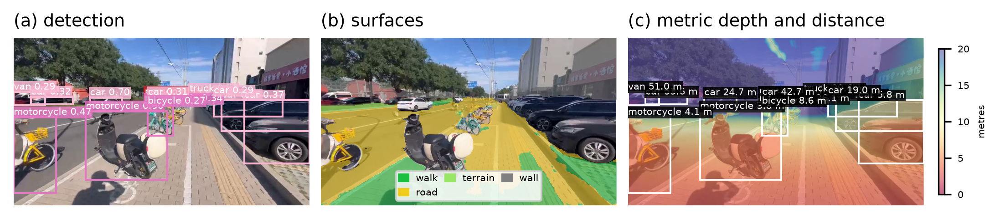

In [46]:
fig, axs = grid(3, rows=1)

# detection
show(axs[0], "(a) detection")
for _, d in d8[d8.conf >= 0.25].iterrows():
    c = CAT_COLORS[d.category]
    axs[0].add_patch(patches.Rectangle((d.x1, d.y1), d.x2 - d.x1, d.y2 - d.y1, fill=False, ec=c, lw=1))
    tag(axs[0], d.x1, d.y1, f"{d.prompt} {d.conf:.2f}", c)

# segmentation
show(axs[1], "(b) surfaces")
groups = np.load(CACHE / "seg" / f"{CLIP}.npz")["groups"][8]
axs[1].imshow(np.ma.masked_equal(groups, 0), cmap=SEG_CMAP, vmin=0, vmax=7, alpha=0.55,
              extent=(0, W, H, 0), interpolation="nearest")
present = [g for g in np.unique(groups) if g > 0]
axs[1].legend(handles=[patches.Patch(color=SURFACE_COLORS[g - 1], label=SURFACE_NAMES[g - 1]) for g in present],
              fontsize=LEGEND, loc="lower center", ncol=min(3, len(present)), framealpha=0.85,
              handlelength=1, columnspacing=0.8, borderpad=0.3)

# metric depth + distance of each object
show(axs[2], "(c) metric depth and distance")
depth = np.load(CACHE / "depth" / f"{CLIP}.npz")["depth"][8].astype(np.float32) * gr.scale
im = axs[2].imshow(depth, cmap="Spectral", vmin=0, vmax=20, alpha=0.6, extent=(0, W, H, 0), interpolation="bilinear")
cb = fig.colorbar(im, ax=axs[2], shrink=0.6, aspect=25)
cb.set_label("metres", fontsize=LEGEND); cb.ax.tick_params(labelsize=LABEL)
for _, d in d8[(d8.conf >= 0.25) & d8.dist_m.notna()].iterrows():
    axs[2].add_patch(patches.Rectangle((d.x1, d.y1), d.x2 - d.x1, d.y2 - d.y1, fill=False, ec="white", lw=0.9))
    tag(axs[2], d.x1, d.y1, f"{d.prompt} {d.dist_m:.1f} m", "black")

save(fig, "figure_perception")
plt.show()

## 3. Figure: scene geometry

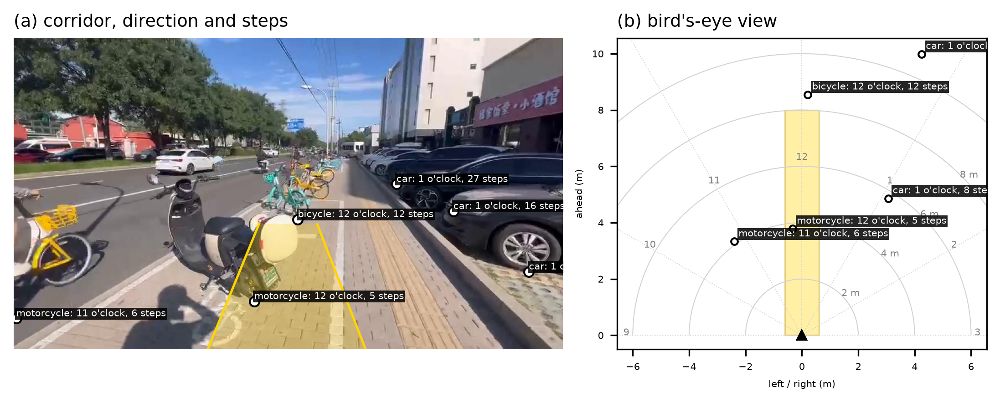

In [47]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 4.4), layout="constrained",
                             width_ratios=[W / H, 2 * XMAX / (YMAX + 0.5)])
label = lambda t: f"{t.prompt}: {t.clock} o'clock, {max(1, round(t.steps))} steps"
main = r.head(6)

# on the frame
show(a1, "(a) corridor, direction and steps")
corridor_on_image(a1)
for _, t in main.iterrows():
    a1.plot(t.ground_x, t.ground_y, "o", color="white", mec="black", ms=5, zorder=3)
    tag(a1, t.ground_x, t.ground_y, label(t), "black")

# bird's-eye, same labels
bev(a2, "(b) bird's-eye view", clock_rays=True)
for _, t in in_view(main).iterrows():
    a2.plot(t.lateral_m, t.forward_m, "o", color="white", mec="black", ms=3.5, zorder=3)
    tag(a2, t.lateral_m + 0.15, t.forward_m + 0.1, label(t), "black")

save(fig, "figure_geometry")
plt.show()

## 4. Figure: tracking and motion prediction

In [48]:
mov = objects[(objects.clip_id == CLIP) & ~objects.flat & (objects.conf >= 0.15)].copy()
mov["track_n"] = mov.groupby("track_id").frame.transform("nunique")
stat = mov[mov.category.isin(STATIC_CATS) & (mov.track_n >= 3) & (mov.dist_m < 20) & (mov.conf >= 0.3)]

steps = {}
for k in range(8):
    a = stat[stat.frame == k].set_index("track_id")[["lateral_m", "forward_m"]]
    b = stat[stat.frame == k + 1].set_index("track_id")[["lateral_m", "forward_m"]]
    common = a.index.intersection(b.index)
    if len(common) == 0:
        steps[k] = None; continue
    A, B = a.loc[common].to_numpy(), b.loc[common].to_numpy()
    R, t = rigid_2d(A, B)
    if len(common) >= 3:
        keep = np.linalg.norm(A @ R.T + t - B, axis=1) < 0.5
        if keep.sum() >= 2:
            R, t = rigid_2d(A[keep], B[keep])
    steps[k] = (R, t)
speeds = [-s[1][1] / DT for s in steps.values() if s is not None]
walk = float(np.clip(np.median(speeds), 0, 2.5)) if speeds else DEFAULT_WALK

M, Ms = np.eye(3), {8: np.eye(3)} # Ms[k]: frame-k coordinates -> frame-8 coordinates
for k in range(7, -1, -1):
    R, t = steps[k] if steps[k] is not None else (np.eye(2), np.array([0, -walk * DT]))
    M = M @ to_h(R, t); Ms[k] = M.copy()

tracks = {}
for tid, g in mov.groupby("track_id"):
    g = g.sort_values("frame")
    if g.frame.nunique() >= 3 and g.frame.iloc[-1] == 8:
        P = np.array([(Ms[k] @ np.array([x, y, 1]))[:2] for k, x, y in zip(g.frame, g.lateral_m, g.forward_m)])
        tracks[tid] = (g.frame.to_numpy(), P)
me = np.array([(Ms[k] @ np.array([0, 0, 1]))[:2] for k in range(9)])   # your own position, frames 0-8
print(f"walking speed {walk:.2f} m/s | {len(tracks)} tracks reaching frame 8")

walking speed 1.20 m/s | 13 tracks reaching frame 8


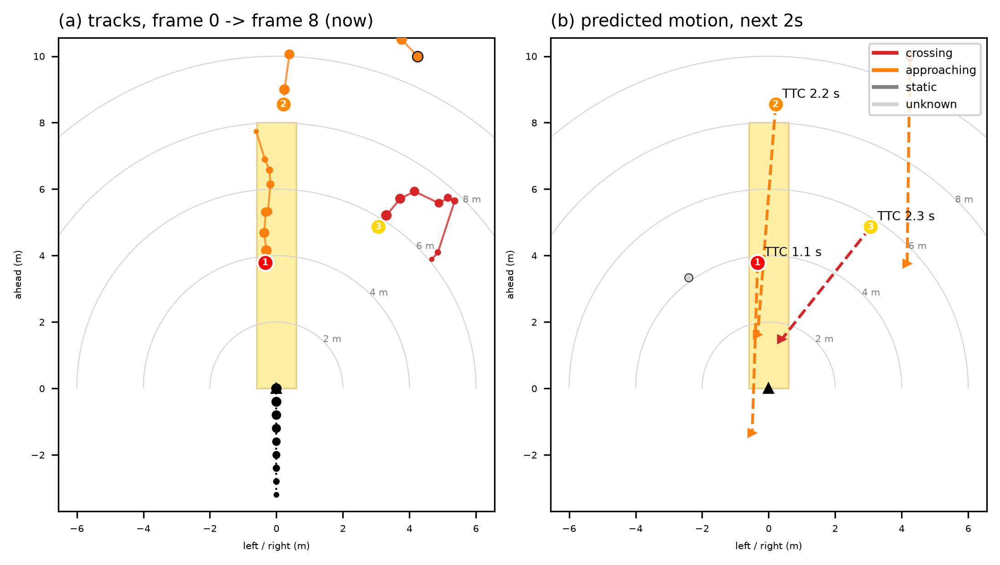

In [49]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 4.4), layout="constrained")
ymin = min(-0.5, me[:, 1].min() - 0.5)

# Tracking: frame 0 (small) -> frame 8 (now)
bev(a1, "(a) tracks, frame 0 -> frame 8 (now)", ymin=ymin)
a1.plot(me[:, 0], me[:, 1], color="black", lw=1, ls=":")
a1.scatter(me[:, 0], me[:, 1], s=4 + 2 * np.arange(9), color="black", zorder=4)
for tid, (fr, P) in tracks.items():
    if abs(P[-1, 0]) > XMAX or not ymin <= P[-1, 1] <= YMAX:
        continue
    c = MOTION_COLORS[motion_of.get(tid, "unknown")]
    a1.plot(P[:, 0], P[:, 1], color=c, lw=1, alpha=0.8)
    a1.scatter(P[:-1, 0], P[:-1, 1], s=3 + 2.5 * fr[:-1], color=c, zorder=3)
    a1.scatter(P[-1, 0], P[-1, 1], s=30, color=c, edgecolor="black", lw=0.6, zorder=4)
for _, t in in_view(top3).iterrows():
    badge(a1, t.lateral_m, t.forward_m, t["rank"], RANK_COLORS[t["rank"]])

# Prediction: where each moving object will be relative to you in the next 2 s
bev(a2, "(b) predicted motion, next 2s", ymin=ymin)
mv = in_view(m8)
a2.scatter(mv.lateral_m, mv.forward_m, s=18, c=[MOTION_COLORS[m] for m in mv.motion], edgecolor="black", lw=0.4, zorder=3)
for _, o in mv[~mv.motion.isin(["static", "unknown"])].iterrows():
    ex, ey = o.lateral_m + 2 * o.vrel_x, o.forward_m + 2 * o.vrel_y
    a2.plot([o.lateral_m, ex], [o.forward_m, ey], ls="--", color=MOTION_COLORS[o.motion], lw=1.5)
    a2.plot(ex, ey, ">", color=MOTION_COLORS[o.motion], ms=4)
    if pd.notna(o.ttc_s):
        a2.text(o.lateral_m + 0.2, o.forward_m + 0.2, f"TTC {o.ttc_s:.1f} s", fontsize=6.5, clip_on=True)
for _, t in in_view(top3).iterrows():
    badge(a2, t.lateral_m, t.forward_m, t["rank"], RANK_COLORS[t["rank"]])

used = [m for m in MOTION_COLORS if m in set(m8.motion)]
a2.legend(handles=[plt.Line2D([0], [0], color=MOTION_COLORS[m], lw=2, label=m.replace("_", " ")) for m in used],
          fontsize=6, loc="upper right", framealpha=0.85)

save(fig, "figure_motion")
plt.show()

## 5. Figure: risk factors, decision

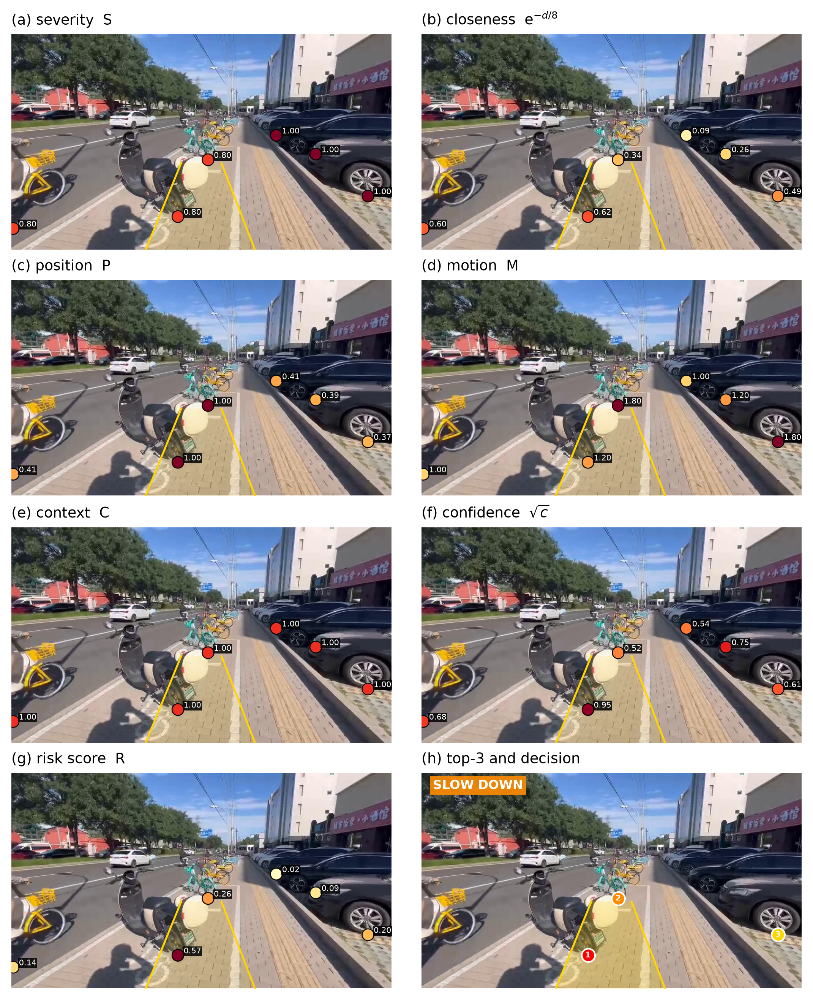

1) motorcycle | 12 o'clock | 5 steps | in your path | approaching
2) bicycle | 12 o'clock | 12 steps | further ahead | approaching
3) car | 1 o'clock | 8 steps | to the side | crossing
Action: slow down for the motorcycle. 

 rank     prompt  dist_m  s_severity  s_close  s_path  s_motion  s_context  sqrt_conf  score
    1 motorcycle    3.80         0.8     0.62    1.00       1.2        1.0       0.95   0.57
    2    bicycle    8.55         0.8     0.34    1.00       1.8        1.0       0.52   0.26
    3        car    5.75         1.0     0.49    0.37       1.8        1.0       0.61   0.20
    4 motorcycle    4.11         0.8     0.60    0.41       1.0        1.0       0.68   0.14
    5        car   10.85         1.0     0.26    0.39       1.2        1.0       0.75   0.09
    6        car   19.04         1.0     0.09    0.41       1.0        1.0       0.54   0.02


In [50]:
FACTORS = [("severity  S", "s_severity", 0.4, 1.0), ("closeness  e$^{-d/8}$", "s_close", 0, 1),
           ("position  P", "s_path", 0, 1), ("motion  M", "s_motion", 0.7, 1.8),
           ("context  C", "s_context", 0.3, 1.3), (r"confidence  $\sqrt{c}$", "sqrt_conf", 0, 1),
           ("risk score  R", "score", 0, None)]
cand = r.head(8).assign(sqrt_conf=lambda x: np.sqrt(x.conf))

fig, axs = grid(8, rows=2 if PORTRAIT else 4)
axs = axs.flat
for ax, (i, (title, col, lo, hi)) in zip(axs, enumerate(FACTORS)):
    show(ax, f"({'abcdefg'[i]}) {title}")
    corridor_on_image(ax, alpha=0.12)
    ax.scatter(cand.ground_x, cand.ground_y, c=cand[col], cmap="YlOrRd", vmin=lo,
               vmax=hi if hi else cand[col].max(), s=55, edgecolor="black", lw=0.6, zorder=3)
    for _, t in cand.iterrows():
        tag(ax, t.ground_x + W * 0.015, t.ground_y, f"{t[col]:.2f}", "black")

# Decision: top-3 + level + action direction
ax = axs[7]
show(ax, "(h) top-3 and decision")
corridor_on_image(ax)
for _, t in top3.iterrows():
    badge(ax, t.ground_x, t.ground_y, t["rank"], RANK_COLORS[t["rank"]])
text, color = LEVEL_STYLE[h.level]
if pd.notna(h.action_clock):
    text += f" → {int(h.action_clock)} o'clock"
    ang = np.radians(h.action_clock * 30)
    ax.annotate("", xy=(W / 2 + 0.25 * H * np.sin(ang), H * 0.95 - 0.25 * H * np.cos(ang)), xytext=(W / 2, H * 0.95),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=2.5))
ax.text(0.03, 0.97, text, transform=ax.transAxes, fontsize=8, fontweight="bold", va="top", color="white",
        bbox=dict(facecolor=color, alpha=0.9, pad=2, lw=0))

save(fig, "figure_risk")
plt.show()

# the same numbers as a small table for the report
print(h.hint, "\n")
print(cand[["rank", "prompt", "dist_m", "s_severity", "s_close", "s_path", "s_motion", "s_context", "sqrt_conf", "score"]]
      .round(2).to_string(index=False))

In [51]:
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300, "font.size": 8})
CORR = "#FFD400"                                   # walking corridor, same in every figure
SURFACE_NAMES = ["walk", "road", "terrain", "water", "stairs", "fence", "wall"]
MOTION_COLORS = {"crossing": "tab:red", "approaching": "tab:orange", "same_direction": "tab:green",
                 "moving_away": "tab:blue", "static": "grey", "unknown": "lightgrey"}

objects = pd.read_parquet(OUT / "objects.parquet")
CAT_COLORS = {c: plt.cm.tab20(i % 20) for i, c in enumerate(sorted(det.category.unique()))}

W, H = Image.open(frame_path(CLIP, 8)).size
PORTRAIT = H > W
r = ranking[ranking.clip_id == CLIP].reset_index(drop=True)
h = hints[hints.clip_id == CLIP].iloc[0]
gr = GEO.loc[(CLIP, 8)]
d8 = det[(det.clip_id == CLIP) & (det.frame == 8)].merge(
    objects[["clip_id", "frame", "track_id", "dist_m"]], on=["clip_id", "frame", "track_id"], how="left")
m8 = motion8[motion8.clip_id == CLIP]
top3 = r.head(3) if h.level != "clear" else r.head(0)
print(h.level, "|", "portrait" if PORTRAIT else "landscape", "|", len(d8), "detections |", len(r), "candidates")

slow | landscape | 18 detections | 6 candidates


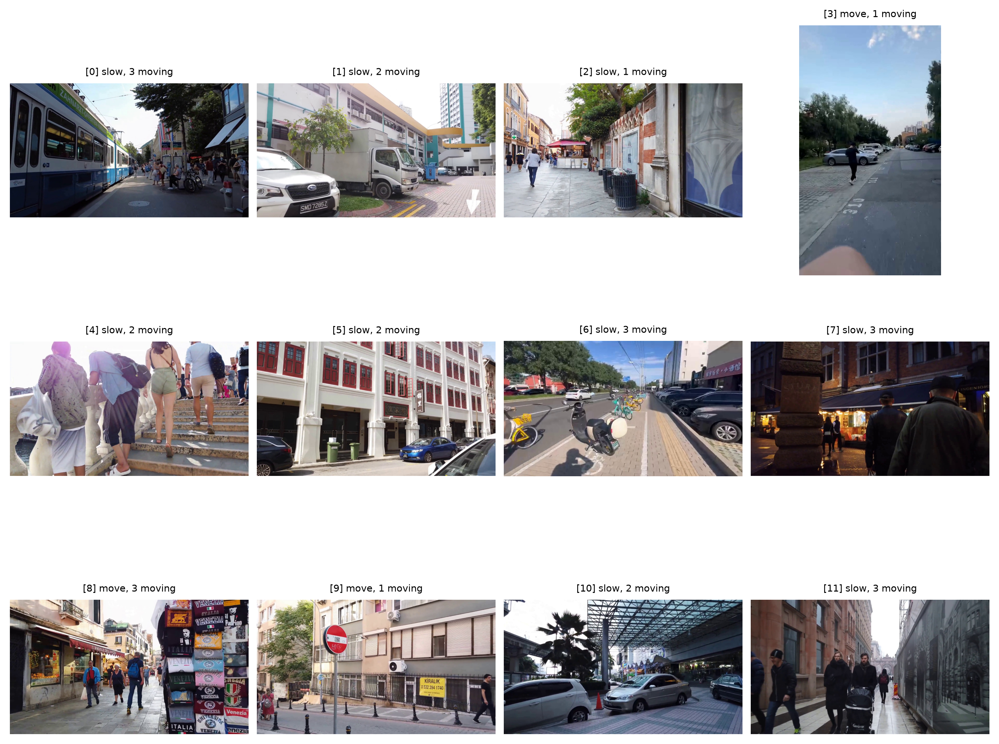

In [15]:
# Find example video
t = pd.read_json(OUTS / "test" / "hints.jsonl", lines=True).set_index("clip_id")
mo = pd.read_parquet(OUTS / "test" / "motion_frame8.parquet")
moving = mo[~mo.motion.isin(["static", "unknown"]) & (mo.dist_m <= 10)].groupby("clip_id").size().rename("n_moving")
pick = t[t.level.isin(["move", "slow"])].join(moving, how="inner")
pick = pick[pick.n_moving.between(1, 3)]

sample = pick.sample(12, random_state=0).index      # change random_state to see others
fig, axs = plt.subplots(3, 4, figsize=(10, 8), layout="constrained")
for i, (ax, c) in enumerate(zip(axs.flat, sample)):
    ax.imshow(Image.open(frame_path(c, 8))); ax.axis("off")
    ax.set_title(f"[{i}] {t.loc[c, 'level']}, {pick.loc[c, 'n_moving']} moving", fontsize=7)
plt.show()

In [16]:
CLIP = sample[6] # get clip id
print(CLIP)

20240914_c2b43e749bd87dd58fbd3fc5a436171d_2m23s.frame


## 6. Figure: Qualitative examples
- (a), (b): the module's top three hazards; (c): the detector's boxes as stored (red) and scaled by 1.5 (dashed), over the segmentation.

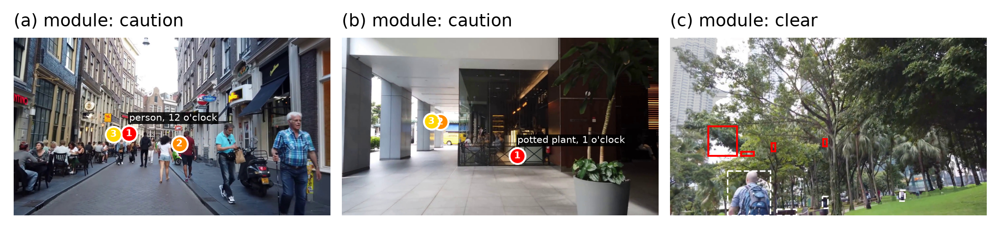

In [52]:
TEST = OUTS / "test"
ex_hints = pd.read_json(TEST / "hints.jsonl", lines=True).set_index("clip_id")
ex_rank = pd.read_parquet(TEST / "ranking.parquet")
ex_det = pd.read_parquet(TEST / "detections.parquet")
EXAMPLES = {"a": "20240918-youtube_short_b47bfc6eff24bcacbc44e6f85504989b_1m7s.frame",
            "b": "20240918-youtube_short_cc8241e21f273fd213a4e857bb320f77_4min19s.frame",
            "c": "20240918-youtube_short_93d2c485fdb77d26f4e13e339c2effa4_2min52s.frame"}
SCALE, CONF_SHOW = 1.5, 0.5         # (c): stored boxes x 1.5 land on the objects; confident boxes only

sizes = {n: Image.open(frame_path(c, 8)).size for n, c in EXAMPLES.items()}
fig, axs = plt.subplots(1, 3, figsize=(7.2, 1.7), layout="constrained",
                        width_ratios=[w / h for w, h in sizes.values()])
for ax, (name, clip) in zip(axs, EXAMPLES.items()):
    W_, H_ = sizes[name]
    ax.imshow(Image.open(frame_path(clip, 8))); ax.set_xlim(0, W_); ax.set_ylim(H_, 0); ax.axis("off")
    ax.set_title(f"({name}) module: {ex_hints.level[clip]}", fontsize=TITLE, loc="left")
    if name == "c":
        groups = np.load(TEST / "cache" / "seg" / f"{clip}.npz")["groups"][8]
        ax.imshow(np.ma.masked_equal(groups, 0), cmap=SEG_CMAP, vmin=0, vmax=7, alpha=0.35,
                  extent=(0, W_, H_, 0), interpolation="nearest")
        for _, d in ex_det[(ex_det.clip_id == clip) & (ex_det.frame == 8) & (ex_det.conf >= CONF_SHOW)].iterrows():
            ax.add_patch(patches.Rectangle((d.x1, d.y1), d.x2 - d.x1, d.y2 - d.y1, fill=False, ec="red", lw=1))
            ax.add_patch(patches.Rectangle((d.x1 * SCALE, d.y1 * SCALE), (d.x2 - d.x1) * SCALE, (d.y2 - d.y1) * SCALE,
                                           fill=False, ec="white", lw=0.8, ls="--"))
    else:
        top = ex_rank[ex_rank.clip_id == clip].sort_values("rank").head(3)
        for _, t in top.iterrows():
            badge(ax, t.ground_x, t.ground_y, t["rank"], RANK_COLORS[t["rank"]])
        t = top.iloc[0]
        tag(ax, t.ground_x, t.ground_y - 0.06 * H_, f"{t.prompt}, {t.clock} o'clock", "black")
save(fig, "figure_qualitative_examples")
plt.show()